# E-commerce Customer Support Automation using MCP
Run the cells top to bottom. Cells 2–5 write the project files; the rest run the experiment. Colab's event loop is already running, so we `await` directly.

## 1. Install (pin `mcp<2`, the FastMCP API)

In [ ]:
!pip -q install "mcp<2" pytest streamlit pandas matplotlib

## 2. Write project files

In [ ]:
%%writefile shop_data.py
"""Creates the mock e-commerce data used in the experiment (JSON files)."""
import json
from pathlib import Path

CUSTOMERS = [
    {"customer_id": "CUST-001", "name": "Aarav Mehta", "tier": "Gold"},
    {"customer_id": "CUST-002", "name": "Diya Shah", "tier": "Silver"},
    {"customer_id": "CUST-003", "name": "Rohan Iyer", "tier": "Bronze"},
]

PRODUCTS = [
    {"product_id": "P-101", "name": "Wireless Mouse", "category": "Accessories", "price": 799, "stock": 42},
    {"product_id": "P-102", "name": "Mechanical Keyboard", "category": "Accessories", "price": 3499, "stock": 0},
    {"product_id": "P-103", "name": "USB-C Hub", "category": "Accessories", "price": 1599, "stock": 15},
    {"product_id": "P-104", "name": "Noise Cancelling Headphones", "category": "Audio", "price": 8999, "stock": 4},
    {"product_id": "P-105", "name": "Bluetooth Speaker", "category": "Audio", "price": 2499, "stock": 0},
    {"product_id": "P-106", "name": "27-inch Monitor", "category": "Displays", "price": 12999, "stock": 3},
    {"product_id": "P-107", "name": "Laptop Stand", "category": "Accessories", "price": 1299, "stock": 28},
    {"product_id": "P-108", "name": "Webcam HD", "category": "Accessories", "price": 2199, "stock": 9},
]

ORDERS = [
    {"order_id": "ORD-1001", "customer_id": "CUST-001", "status": "Delivered",
     "order_date": "2026-10-08", "delivered_date": "2026-10-15", "carrier": "BlueDart",
     "tracking_id": "BD7781234",
     "items": [{"product_id": "P-101", "qty": 1, "price": 799}, {"product_id": "P-103", "qty": 1, "price": 1599}],
     "total": 2398},
    {"order_id": "ORD-1002", "customer_id": "CUST-002", "status": "Shipped",
     "order_date": "2026-10-19", "eta": "2026-10-24", "carrier": "Delhivery",
     "tracking_id": "DL5543210",
     "items": [{"product_id": "P-104", "qty": 1, "price": 8999}], "total": 8999},
    {"order_id": "ORD-1003", "customer_id": "CUST-001", "status": "Delivered",
     "order_date": "2026-08-01", "delivered_date": "2026-08-06", "carrier": "BlueDart",
     "tracking_id": "BD6620011",
     "items": [{"product_id": "P-107", "qty": 1, "price": 1299}], "total": 1299},
    {"order_id": "ORD-1004", "customer_id": "CUST-003", "status": "Processing",
     "order_date": "2026-10-21", "carrier": None, "tracking_id": None,
     "items": [{"product_id": "P-108", "qty": 1, "price": 2199}], "total": 2199},
    {"order_id": "ORD-1005", "customer_id": "CUST-002", "status": "Delivered",
     "order_date": "2026-10-14", "delivered_date": "2026-10-18", "carrier": "EcomExpress",
     "tracking_id": "EE9900123",
     "items": [{"product_id": "P-106", "qty": 1, "price": 12999}], "total": 12999},
    {"order_id": "ORD-1006", "customer_id": "CUST-003", "status": "Cancelled",
     "order_date": "2026-10-05", "carrier": None, "tracking_id": None,
     "items": [{"product_id": "P-101", "qty": 1, "price": 799}], "total": 799},
    {"order_id": "ORD-1007", "customer_id": "CUST-001", "status": "Delivered",
     "order_date": "2026-10-06", "delivered_date": "2026-10-11", "carrier": "Delhivery",
     "tracking_id": "DL1209876",
     "items": [{"product_id": "P-103", "qty": 2, "price": 1599}], "total": 3198},
]


def create_sample_data(path="shop_data") -> Path:
    """(Re)create the data files and clear any refunds made in earlier runs."""
    root = Path(path)
    root.mkdir(parents=True, exist_ok=True)
    for name, data in [("customers", CUSTOMERS), ("products", PRODUCTS), ("orders", ORDERS)]:
        (root / f"{name}.json").write_text(json.dumps(data, indent=2), encoding="utf-8")
    (root / "refunds.jsonl").unlink(missing_ok=True)
    return root


if __name__ == "__main__":
    print("Created", create_sample_data().resolve())

Writing shop_data.py


In [ ]:
%%writefile ecommerce_server.py
"""MCP server for E-commerce Customer Support (FastMCP, stdio transport)."""
import asyncio
import json
import os
import re
import uuid
from datetime import date, datetime
from pathlib import Path

from mcp.server.fastmcp import FastMCP

DATA_DIR = Path(os.environ.get("SHOP_DATA_DIR", "shop_data")).resolve()
TODAY = date.fromisoformat(os.environ.get("SHOP_TODAY", "2026-10-22"))  # fixed "today" => reproducible
REFUND_WINDOW_DAYS = 30
ORDER_RE = re.compile(r"^ORD-\d{4,}$")
_FLAKY_SEEN = set()  # used only by the retry demo

mcp = FastMCP("E-commerce Support Server")


class NotFound(ValueError):
    """Requested record does not exist (input error)."""


# ---------------------------------------------------------------- helpers
def _ok(**data) -> str:
    return json.dumps({"status": "ok", **data})


def _err(error_type: str, message: str) -> str:
    return json.dumps({"status": "error", "error_type": error_type, "error": message})


def _handle(e: Exception) -> str:
    if isinstance(e, PermissionError):
        return _err("security_error", str(e))
    if isinstance(e, ValueError):  # includes NotFound
        return _err("input_error", str(e))
    return _err("execution_error", f"{type(e).__name__}: {e}")


async def _latency(ms: int):
    if ms and ms > 0:
        await asyncio.sleep(min(ms, 2000) / 1000)


def _load(name: str):
    return json.loads((DATA_DIR / f"{name}.json").read_text(encoding="utf-8"))


def _order(order_id: str) -> dict:
    if not ORDER_RE.match(order_id or ""):
        raise ValueError(f"Invalid order id '{order_id}' (expected format ORD-1234)")
    for o in _load("orders"):
        if o["order_id"] == order_id:
            return o
    raise NotFound(f"Order {order_id} not found")


def _product(term: str) -> dict:
    term = (term or "").strip().lower()
    if not term:
        raise ValueError("Empty product name/id")
    products = _load("products")
    for p in products:
        if p["product_id"].lower() == term:
            return p
    for p in products:
        if term in p["name"].lower():
            return p
    raise NotFound(f"Product '{term}' not found")


def _existing_refund(order_id: str):
    f = DATA_DIR / "refunds.jsonl"
    if f.exists():
        for line in f.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line)
                if r["order_id"] == order_id:
                    return r
    return None


def _eligibility(order: dict) -> dict:
    existing = _existing_refund(order["order_id"])
    days = None
    if order["status"] == "Delivered":
        days = (TODAY - date.fromisoformat(order["delivered_date"])).days
    eligible = False
    if existing:
        reason = f"Already refunded ({existing['refund_id']})"
    elif order["status"] != "Delivered":
        reason = f"Order is {order['status']}; only delivered orders can be refunded"
    elif days > REFUND_WINDOW_DAYS:
        reason = f"Return window of {REFUND_WINDOW_DAYS} days expired ({days} days since delivery)"
    else:
        eligible, reason = True, f"Within {REFUND_WINDOW_DAYS}-day return window ({days} days since delivery)"
    return {"order_id": order["order_id"], "eligible": eligible, "reason": reason,
            "days_since_delivery": days, "window_days": REFUND_WINDOW_DAYS,
            "refund_amount": order["total"], "already_refunded": existing is not None}


# ------------------------------------------------------------------ tools
@mcp.tool()
async def track_order(order_id: str, customer_id: str = "", simulate_latency_ms: int = 0) -> str:
    """Get order status and shipment details (LOW risk). If customer_id is given it must own the order."""
    try:
        await _latency(simulate_latency_ms)
        o = _order(order_id)
        if customer_id and customer_id != o["customer_id"]:
            raise PermissionError("Order does not belong to this customer")
        names = {p["product_id"]: p["name"] for p in _load("products")}
        items = [{"product": names.get(i["product_id"], i["product_id"]), **i} for i in o["items"]]
        return _ok(order_id=o["order_id"], customer_id=o["customer_id"], order_status=o["status"],
                   order_date=o["order_date"], delivered_date=o.get("delivered_date"),
                   eta=o.get("eta"), carrier=o["carrier"], tracking_id=o["tracking_id"],
                   items=items, total=o["total"])
    except Exception as e:
        return _handle(e)


@mcp.tool()
async def search_products(query: str, max_results: int = 5, simulate_latency_ms: int = 0) -> str:
    """Search the catalogue by name or category (LOW risk)."""
    try:
        await _latency(simulate_latency_ms)
        q = (query or "").strip().lower()
        if not q:
            raise ValueError("Empty search query")
        hits = [{**p, "in_stock": p["stock"] > 0} for p in _load("products")
                if q in p["name"].lower() or q in p["category"].lower()]
        return _ok(query=query, products=hits[:max_results], count=len(hits))
    except Exception as e:
        return _handle(e)


@mcp.tool()
async def check_stock(product: str, simulate_latency_ms: int = 0,
                      simulate_transient_error: bool = False) -> str:
    """Check inventory for a product id or name (LOW risk). simulate_transient_error is for the retry demo."""
    try:
        await _latency(simulate_latency_ms)
        if simulate_transient_error and product not in _FLAKY_SEEN:
            _FLAKY_SEEN.add(product)
            raise RuntimeError("Temporary inventory service error")
        p = _product(product)
        level = "Out of stock" if p["stock"] == 0 else ("Low stock" if p["stock"] <= 5 else "In stock")
        return _ok(product_id=p["product_id"], name=p["name"], stock=p["stock"], availability=level,
                   price=p["price"])
    except Exception as e:
        return _handle(e)


@mcp.tool()
async def check_refund_eligibility(order_id: str, simulate_latency_ms: int = 0) -> str:
    """Check whether an order can be refunded (LOW risk, read-only)."""
    try:
        await _latency(simulate_latency_ms)
        return _ok(**_eligibility(_order(order_id)))
    except Exception as e:
        return _handle(e)


@mcp.tool()
async def process_refund(order_id: str, reason: str, amount: int = 0) -> str:
    """Issue a refund (HIGH risk: changes money/state). amount=0 means the full order total."""
    try:
        o = _order(order_id)
        el = _eligibility(o)  # defence in depth: the server re-checks eligibility itself
        if not el["eligible"]:
            raise ValueError(f"Refund not allowed: {el['reason']}")
        amt = amount or o["total"]
        if amt <= 0 or amt > o["total"]:
            raise ValueError(f"Invalid refund amount {amt} (order total {o['total']})")
        rec = {"refund_id": "RF-" + uuid.uuid4().hex[:6].upper(), "order_id": order_id, "amount": amt,
               "reason": reason, "timestamp": datetime.now().isoformat(timespec="seconds")}
        with open(DATA_DIR / "refunds.jsonl", "a", encoding="utf-8") as f:
            f.write(json.dumps(rec) + "\n")
        return _ok(**rec, message="Refund initiated")
    except Exception as e:
        return _handle(e)


if __name__ == "__main__":
    mcp.run(transport="stdio")

Writing ecommerce_server.py


In [ ]:
%%writefile support_automation.py
"""MCP client + planner, supervisor, policy, validator, recovery, tracing, benchmark
for the E-commerce Customer Support Automation System."""
import asyncio
import json
import logging
import os
import re
import statistics
import sys
import time
import uuid
from contextlib import asynccontextmanager
from datetime import datetime
from pathlib import Path

from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters, stdio_client

BASE = Path(__file__).resolve().parent
SERVER_PATH = BASE / "ecommerce_server.py"
LOG_DIR = Path("mcp_logs")
LOG_DIR.mkdir(exist_ok=True)
TRACE_FILE = LOG_DIR / "mcp_traces.jsonl"
REPORT_FILE = LOG_DIR / "support_automation_report.json"

logging.basicConfig(filename=LOG_DIR / "execution.log", level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("support_automation")

# ---- risk / policy / classification tables ----
TOOL_RISK = {"track_order": "LOW", "search_products": "LOW", "check_stock": "LOW",
             "check_refund_eligibility": "LOW", "process_refund": "HIGH"}
REFUND_AUTO_LIMIT = 5000            # refunds above this are escalated to a human agent
RETRYABLE = {"timeout", "execution_error"}
MAX_RETRIES = 2
CALL_TIMEOUT = 60
EXPECTED_KEYS = {"track_order": ["order_status", "items"], "search_products": ["products"],
                 "check_stock": ["stock"], "check_refund_eligibility": ["eligible"],
                 "process_refund": ["refund_id"]}


# ============================================================ connection
@asynccontextmanager
async def mcp_session(data_dir="shop_data"):
    """Start the MCP server over stdio and yield an initialized ClientSession."""
    params = StdioServerParameters(
        command=sys.executable, args=[str(SERVER_PATH)],
        env={**os.environ, "SHOP_DATA_DIR": str(Path(data_dir).resolve())})
    # errlog -> file: notebooks' sys.stderr has no fileno() and would crash
    with open(LOG_DIR / "server_stderr.log", "a") as errlog:
        async with stdio_client(params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                yield session


async def discover_tools(session):
    tools = await session.list_tools()
    return {t.name: t.inputSchema for t in tools.tools}


# ================================================================ agents
def _stock_term(request: str):
    """Product for a stock check: product id, 'is X in stock', 'stock of X', or quoted text."""
    m = re.search(r"\bP-\d+\b", request, re.I)
    if m:
        return m.group(0).upper()
    m = re.search(r"\b(?:is|are)\s+(?:the\s+)?(.+?)\s+(?:in stock|available)\b", request, re.I)
    if m:
        return m.group(1).strip()
    m = re.search(r"\b(?:stock|availability|available)\s*(?:of|for)?\s+(?:the\s+)?(.+?)(?:\s+(?:and|with)\b|[?.!]|$)",
                  request, re.I)
    if m:
        return m.group(1).strip()
    m = re.search(r"[\"']([^\"']+)[\"']", request)
    return m.group(1) if m else ""


def _search_term(request: str):
    """Query for a catalogue search: 'search for X', 'find X', 'browse X', or quoted text."""
    m = re.search(r"\b(?:search(?:\s+for)?|find|browse|look for)\s+(?:the\s+|any\s+)?(.+?)(?:\s+(?:and|with|in)\b|[?.!]|$)",
                  request, re.I)
    if m:
        return m.group(1).strip()
    m = re.search(r"[\"']([^\"']+)[\"']", request)
    return m.group(1) if m else ""


def plan_request(request: str):
    """Planner: natural language -> structured tasks (with dependencies)."""
    text = request.lower()
    om = re.search(r"\bORD-\d+\b", request, re.I)
    cm = re.search(r"\bCUST-\d+\b", request, re.I)
    order = om.group(0).upper() if om else ""
    cust = cm.group(0).upper() if cm else ""
    tasks = []

    def add(tool, args, deps=None):
        tid = f"TASK-{len(tasks) + 1:03d}"
        tasks.append({"task_id": tid, "tool": tool, "args": args, "depends_on": deps or []})
        return tid

    refund_action = bool(re.search(r"\b(process|issue|approve|initiate|grant)\b.*\brefund\b", text)
                         or re.search(r"\brefund\s+(?:order\s+)?ord-\d+", text))
    wants_track = bool(re.search(r"\b(track|status|where is|shipping|shipped|deliver\w*)\b", text))
    wants_elig = bool(re.search(r"\beligib\w*|\brefund\b|\breturn\b", text))
    wants_stock = bool(re.search(r"\bstock\b|\bavailab\w*", text))
    wants_search = bool(re.search(r"\b(search|find|browse|look for)\b", text))

    track_id = elig_id = None
    if refund_action or wants_track or (order and not (wants_elig or wants_stock or wants_search)):
        targs = {"order_id": order}
        if cust:
            targs["customer_id"] = cust
        track_id = add("track_order", targs)
    if refund_action or wants_elig:
        elig_id = add("check_refund_eligibility", {"order_id": order})
    if wants_stock:
        add("check_stock", {"product": _stock_term(request)})
    if wants_search:
        add("search_products", {"query": _search_term(request)})
    if refund_action:
        rm = re.search(r"(?:because|reason[: ]+|since)\s+(.+)$", request, re.I)
        am = re.search(r"(?:₹|rs\.?|inr)\s*(\d+)", request, re.I)
        args = {"order_id": order, "reason": rm.group(1).strip() if rm else "Customer request"}
        if am:
            args["amount"] = int(am.group(1))
        add("process_refund", args, [track_id, elig_id])
    return tasks


def supervise(tasks, available):
    """Supervisor: tool must exist and required arguments must be present."""
    approved, rejected = [], []
    for t in tasks:
        schema = available.get(t["tool"])
        if schema is None:
            rejected.append({**t, "reason": f"tool '{t['tool']}' not exposed by server"})
            continue
        missing = [r for r in schema.get("required", [])
                   if not isinstance(t["args"].get(r), str) or not t["args"].get(r).strip()]
        if missing:
            rejected.append({**t, "reason": f"missing/empty argument(s): {missing}"})
        else:
            approved.append(t)
    return approved, rejected


def policy_check(tasks, approve_high_risk=False):
    """Safety layer: LOW/MEDIUM allowed; HIGH needs explicit human approval."""
    allowed, blocked = [], []
    for t in tasks:
        risk = TOOL_RISK.get(t["tool"], "HIGH")
        t = {**t, "risk": risk}
        if risk == "HIGH" and not approve_high_risk:
            blocked.append({**t, "reason": "HIGH-risk tool needs human approval (approve_high_risk=False)"})
        else:
            allowed.append(t)
    return allowed, blocked


def gate(task, results):
    """Phase-2 business gate before a dependent task runs."""
    if task["tool"] != "process_refund":
        return True, "ok"
    el = next((r for r in results.values() if r["tool"] == "check_refund_eligibility"), None)
    if not el or not el["valid"]:
        return False, "eligibility check missing or invalid"
    if not el["payload"].get("eligible"):
        return False, f"not eligible: {el['payload'].get('reason')}"
    amount = task["args"].get("amount") or el["payload"].get("refund_amount", 0)
    if amount > REFUND_AUTO_LIMIT:
        return False, (f"refund amount {amount} exceeds auto-approval limit "
                       f"{REFUND_AUTO_LIMIT}; escalate to a human agent")
    return True, "ok"


def validate(tool, payload):
    """Validator: status + structure of the result."""
    if payload.get("status") != "ok":
        return False, f"status={payload.get('status')} ({payload.get('error_type')})"
    missing = [k for k in EXPECTED_KEYS.get(tool, []) if k not in payload]
    if missing:
        return False, f"missing keys {missing}"
    return True, "ok"


# ===================================================== execution + tracing
def write_trace(rec):
    with open(TRACE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")


def read_traces(limit=200):
    if not TRACE_FILE.exists():
        return []
    lines = TRACE_FILE.read_text(encoding="utf-8").strip().splitlines()[-limit:]
    return [json.loads(x) for x in lines]


async def execute_task(session, task, trace_id, max_retries=MAX_RETRIES):
    """Call one MCP tool with failure classification, limited retry and tracing."""
    attempt = 0
    while True:
        attempt += 1
        t0 = time.perf_counter()
        try:
            res = await asyncio.wait_for(
                session.call_tool(task["tool"], arguments=task["args"]), CALL_TIMEOUT)
            text = "".join(getattr(c, "text", "") for c in res.content)
            if res.isError:
                payload = {"status": "error", "error_type": "tool_error", "error": text[:300]}
            else:
                try:
                    payload = json.loads(text)
                except json.JSONDecodeError:
                    payload = {"status": "error", "error_type": "execution_error",
                               "error": "non-JSON tool output"}
        except asyncio.TimeoutError:
            payload = {"status": "error", "error_type": "timeout", "error": "client timeout"}
        except Exception as e:  # noqa: BLE001
            payload = {"status": "error", "error_type": "execution_error", "error": str(e)}
        ms = round((time.perf_counter() - t0) * 1000, 2)
        ok = payload.get("status") == "ok"
        write_trace({"trace_id": trace_id, "task_id": task["task_id"], "tool": task["tool"],
                     "arguments": task["args"], "status": "success" if ok else "failure",
                     "attempt": attempt, "execution_ms": ms,
                     "timestamp": datetime.now().isoformat(timespec="seconds"),
                     "error": None if ok else payload.get("error")})
        log.info("%s %s %s attempt=%d %.2fms ok=%s", trace_id, task["task_id"], task["tool"],
                 attempt, ms, ok)
        err_type = payload.get("error_type")
        if not ok and err_type in RETRYABLE and attempt <= max_retries:
            log.warning("%s retrying (%s)", task["task_id"], err_type)
            await asyncio.sleep(0.2 * attempt)
            continue
        valid, vmsg = validate(task["tool"], payload)
        return {"task_id": task["task_id"], "tool": task["tool"], "args": task["args"],
                "risk": task.get("risk", TOOL_RISK.get(task["tool"])),
                "status": "success" if ok else "failure", "error_type": err_type,
                "error": payload.get("error"), "attempts": attempt, "ms": ms,
                "valid": valid, "validation": vmsg, "payload": payload}


async def run_workflow(request, data_dir="shop_data", mode="parallel", approve_high_risk=False):
    """Full pipeline: plan -> supervise -> policy -> execute (phases) -> validate -> report."""
    trace_id = "TRACE-" + uuid.uuid4().hex[:8].upper()
    t_start = time.perf_counter()
    async with mcp_session(data_dir) as session:
        available = await discover_tools(session)
        plan = plan_request(request)
        approved, rejected = supervise(plan, available)
        approved, blocked = policy_check(approved, approve_high_risk)
        for r in rejected + blocked:
            write_trace({"trace_id": trace_id, "task_id": r["task_id"], "tool": r["tool"],
                         "arguments": r["args"], "status": "rejected",
                         "timestamp": datetime.now().isoformat(timespec="seconds"),
                         "error": r.get("reason")})

        independent = [t for t in approved if not t["depends_on"]]
        dependent = [t for t in approved if t["depends_on"]]
        results = {}

        # Phase 1: independent tasks (parallel or sequential)
        p1 = time.perf_counter()
        if mode == "parallel":
            out = await asyncio.gather(*[execute_task(session, t, trace_id) for t in independent])
        else:
            out = [await execute_task(session, t, trace_id) for t in independent]
        for r in out:
            results[r["task_id"]] = r
        p1_ms = round((time.perf_counter() - p1) * 1000, 2)

        # Phase 2: dependency + business-rule validation, Phase 3: dependent tasks (sequential)
        p3 = time.perf_counter()
        for t in dependent:
            bad = [d for d in t["depends_on"] if not (d in results and results[d]["valid"])]
            ok_gate, gmsg = (False, f"dependency {bad} failed validation") if bad else gate(t, results)
            if not ok_gate:
                results[t["task_id"]] = {
                    "task_id": t["task_id"], "tool": t["tool"], "args": t["args"],
                    "risk": t.get("risk"), "status": "skipped", "error_type": "policy_gate",
                    "valid": False, "validation": gmsg, "error": gmsg, "ms": 0, "attempts": 0,
                    "payload": {}}
                write_trace({"trace_id": trace_id, "task_id": t["task_id"], "tool": t["tool"],
                             "arguments": t["args"], "status": "skipped",
                             "timestamp": datetime.now().isoformat(timespec="seconds"), "error": gmsg})
                continue
            results[t["task_id"]] = await execute_task(session, t, trace_id)
        p3_ms = round((time.perf_counter() - p3) * 1000, 2)

    ordered = [results[t["task_id"]] for t in approved if t["task_id"] in results]
    report = {
        "trace_id": trace_id, "request": request, "mode": mode,
        "approve_high_risk": approve_high_risk,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "tools_discovered": list(available), "plan": plan,
        "rejected": rejected, "blocked_by_policy": blocked, "results": ordered,
        "summary": {
            "tasks_planned": len(plan), "succeeded": sum(r["status"] == "success" for r in ordered),
            "failed": sum(r["status"] == "failure" for r in ordered),
            "skipped": sum(r["status"] == "skipped" for r in ordered),
            "rejected": len(rejected), "blocked": len(blocked),
            "phase1_ms": p1_ms, "phase3_ms": p3_ms,
            "total_ms": round((time.perf_counter() - t_start) * 1000, 2),
            "dop": len(independent) if mode == "parallel" else 1,
        },
    }
    REPORT_FILE.write_text(json.dumps(report, indent=2), encoding="utf-8")
    return report


# ============================================================ extras
async def failure_demo(data_dir="shop_data"):
    """Failure classification: security / input errors stop at once, transient errors retry."""
    trace_id = "TRACE-" + uuid.uuid4().hex[:8].upper()
    cases = [
        ("Security: order of another customer", "track_order",
         {"order_id": "ORD-1001", "customer_id": "CUST-002"}),
        ("Input: unknown order", "track_order", {"order_id": "ORD-9999"}),
        ("Input: bad order id format", "track_order", {"order_id": "1001"}),
        ("Input: refund on shipped order (server re-check)", "process_refund",
         {"order_id": "ORD-1002", "reason": "test"}),
        ("Transient error -> retry -> success", "check_stock",
         {"product": "P-101", "simulate_transient_error": True}),
    ]
    out = []
    async with mcp_session(data_dir) as session:
        for i, (label, tool, args) in enumerate(cases, 1):
            r = await execute_task(session, {"task_id": f"TASK-{i:03d}", "tool": tool, "args": args}, trace_id)
            r["case"] = label
            out.append(r)
    return out


async def run_benchmark(data_dir="shop_data", runs=5, latency_ms=0):
    """Variation: 4 independent tool calls, sequential vs parallel, repeated `runs` times.
    latency_ms simulates slower back-end services (0 = real, near-instant calls)."""
    L = {"simulate_latency_ms": latency_ms}
    calls = [("track_order", {"order_id": "ORD-1001", **L}),
             ("search_products", {"query": "mouse", **L}),
             ("check_stock", {"product": "P-101", **L}),
             ("check_refund_eligibility", {"order_id": "ORD-1001", **L})]
    rows = []
    async with mcp_session(data_dir) as session:
        await session.call_tool("check_stock", arguments={"product": "P-101"})  # warm-up
        for i in range(1, runs + 1):
            t0 = time.perf_counter()
            for tool, args in calls:
                await session.call_tool(tool, arguments=args)
            seq = (time.perf_counter() - t0) * 1000
            t0 = time.perf_counter()
            await asyncio.gather(*[session.call_tool(t, arguments=a) for t, a in calls])
            par = (time.perf_counter() - t0) * 1000
            rows.append({"run": i, "sequential_ms": round(seq, 2), "parallel_ms": round(par, 2)})
    avg_s = statistics.mean(r["sequential_ms"] for r in rows)
    avg_p = statistics.mean(r["parallel_ms"] for r in rows)
    summary = {"tasks": len(calls), "runs": runs, "simulated_latency_ms": latency_ms,
               "avg_sequential_ms": round(avg_s, 2), "avg_parallel_ms": round(avg_p, 2),
               "avg_time_per_tool_ms": round(avg_s / len(calls), 2),
               "time_reduction_pct": round((avg_s - avg_p) / avg_s * 100, 2)}
    (LOG_DIR / f"performance_comparison_{latency_ms}ms.json").write_text(
        json.dumps({"rows": rows, "summary": summary}, indent=2))
    return rows, summary

Writing support_automation.py


In [ ]:
%%writefile streamlit_app.py
import asyncio
import json
from pathlib import Path

import pandas as pd
import streamlit as st

from shop_data import create_sample_data
from support_automation import (REFUND_AUTO_LIMIT, REPORT_FILE, TOOL_RISK, discover_tools,
                                failure_demo, mcp_session, read_traces, run_benchmark, run_workflow)

st.set_page_config(page_title="E-commerce Support MCP", page_icon="🛒", layout="wide")
st.title("🛒 E-commerce Customer Support Automation using MCP")
st.caption("Planner → Supervisor → Policy → MCP Client → MCP Server (5 tools) → Validator → Trace → Report")

with st.sidebar:
    st.header("Settings")
    data_dir = st.text_input("Shop data directory", "shop_data")
    mode = st.radio("Phase-1 execution", ["parallel", "sequential"])
    approve = st.checkbox("Human approves HIGH-risk actions (refunds)", value=False)
    st.caption(f"Refunds above ₹{REFUND_AUTO_LIMIT} are always escalated to a human agent.")
    if st.button("Reset mock data (clears refunds)"):
        create_sample_data(data_dir)
        st.success("Data reset")
    st.markdown("**Tool risk levels**")
    st.table(pd.DataFrame(TOOL_RISK.items(), columns=["tool", "risk"]))

if not Path(data_dir).exists():
    create_sample_data(data_dir)

tab_run, tab_tools, tab_bench, tab_fail, tab_data, tab_trace = st.tabs(
    ["▶ Run request", "🔍 Tool discovery", "⏱ Performance", "🛡 Security & failures",
     "🗂 Shop data", "📜 Traces"])

# ---------------------------------------------------------------- run
with tab_run:
    examples = [
        "Track order ORD-1002 and check stock of P-104",
        "Search for headphones and check stock of Wireless Mouse",
        "Check refund eligibility for ORD-1003",
        "Where is my order ORD-1004",
        "Track order ORD-1001 for CUST-002",
        "Refund order ORD-1001 because the item is defective",
        "Refund order ORD-1005 because screen is cracked",
        "Refund order ORD-1003 because it arrived late",
    ]
    pick = st.selectbox("Example requests", examples)
    request = st.text_input("Customer-support request", pick)
    st.caption("Refund examples need the *approve* checkbox in the sidebar. "
               "ORD-1001 refunds once; ORD-1005 exceeds the limit; ORD-1003 is outside the 30-day window.")
    if st.button("Run workflow", type="primary"):
        with st.spinner("Running through MCP..."):
            rep = asyncio.run(run_workflow(request, data_dir, mode, approve))
        s = rep["summary"]
        c = st.columns(6)
        c[0].metric("Trace ID", rep["trace_id"])
        c[1].metric("Succeeded", s["succeeded"])
        c[2].metric("Failed", s["failed"])
        c[3].metric("Skipped / blocked", f"{s['skipped']} / {s['blocked']}")
        c[4].metric("Total time", f"{s['total_ms']} ms")
        c[5].metric("DOP (phase 1)", s["dop"])
        st.subheader("Plan")
        st.dataframe(pd.DataFrame(rep["plan"]), width="stretch")
        for r in rep["rejected"] + rep["blocked_by_policy"]:
            st.warning(f"{r['task_id']} {r['tool']} not executed: {r.get('reason')}")
        for r in rep["results"]:
            if r["status"] == "skipped":
                st.info(f"{r['task_id']} {r['tool']} skipped: {r['validation']}")
        st.subheader("Execution results")
        if rep["results"]:
            st.dataframe(pd.DataFrame([{k: v for k, v in r.items() if k not in ("payload", "args")}
                                       for r in rep["results"]]), width="stretch")
        for r in rep["results"]:
            with st.expander(f"{r['task_id']} · {r['tool']} · {r['status']}"):
                st.json(r["payload"] or {"note": r["validation"]})
        st.download_button("Download report JSON", json.dumps(rep, indent=2),
                           file_name="support_automation_report.json")

# ---------------------------------------------------------------- tools
with tab_tools:
    if st.button("Discover tools (session.list_tools())"):
        async def _d():
            async with mcp_session(data_dir) as s:
                return await discover_tools(s)
        tools = asyncio.run(_d())
        st.success(f"{len(tools)} tools discovered over stdio")
        for name, schema in tools.items():
            with st.expander(f"{name}  [{TOOL_RISK.get(name)}]"):
                st.json(schema)

# ---------------------------------------------------------------- perf
with tab_bench:
    c1, c2 = st.columns(2)
    runs = c1.slider("Runs", 3, 10, 5)
    lat = c2.select_slider("Simulated back-end latency per tool (ms)", [0, 25, 50, 100, 200], value=0)
    if st.button("Run sequential vs parallel benchmark"):
        rows, summ = asyncio.run(run_benchmark(data_dir, runs, lat))
        df = pd.DataFrame(rows).set_index("run")
        st.dataframe(df, width="stretch")
        st.bar_chart(df)
        st.json(summ)
        if lat == 0:
            st.info("Real calls take only a few ms, so scheduling/stdio overhead is comparable to the work. "
                    "Re-run with 50–100 ms latency to see the benefit of parallel execution.")
        else:
            st.info("With slower back-end tools the 4 calls overlap, so parallel time ≈ one tool call.")

# ---------------------------------------------------------------- failures
with tab_fail:
    st.write("Security and input errors stop immediately (**attempts = 1**); a transient error is "
             "**retried** and then succeeds (**attempts = 2**).")
    if st.button("Run security / failure demo"):
        out = asyncio.run(failure_demo(data_dir))
        st.dataframe(pd.DataFrame([{k: v for k, v in r.items() if k not in ("payload", "args", "risk")}
                                   for r in out])[["case", "tool", "status", "error_type", "attempts", "error"]],
                     width="stretch")

# ---------------------------------------------------------------- data
with tab_data:
    for name in ["orders", "products", "customers"]:
        st.subheader(name.capitalize())
        f = Path(data_dir) / f"{name}.json"
        if f.exists():
            df = pd.DataFrame(json.loads(f.read_text()))
            if name == "orders":
                df["items"] = df["items"].apply(lambda x: ", ".join(f"{i['product_id']}×{i['qty']}" for i in x))
            st.dataframe(df, width="stretch")
    rf = Path(data_dir) / "refunds.jsonl"
    st.subheader("Refunds issued")
    if rf.exists():
        st.dataframe(pd.DataFrame([json.loads(l) for l in rf.read_text().splitlines() if l.strip()]),
                     width="stretch")
    else:
        st.caption("No refunds issued yet.")

# ---------------------------------------------------------------- traces
with tab_trace:
    traces = read_traces(500)
    if traces:
        st.dataframe(pd.DataFrame(traces).iloc[::-1], width="stretch")
    else:
        st.info("No traces yet – run a workflow first.")
    if REPORT_FILE.exists():
        st.download_button("Download latest report", REPORT_FILE.read_text(),
                           file_name="support_automation_report.json", key="dl2")

Writing streamlit_app.py


## 3. Create mock shop data and discover tools over MCP (stdio)

In [ ]:
from shop_data import create_sample_data
from support_automation import *
import json, pandas as pd
print("Created:", create_sample_data().resolve())

async with mcp_session("shop_data") as s:
    tools = await discover_tools(s)
for name, schema in tools.items():
    print(f"{name:26s} risk={TOOL_RISK[name]:5s} args={list(schema['properties'])}")

Created: /content/shop_data
track_order                risk=LOW   args=['order_id', 'customer_id', 'simulate_latency_ms']
search_products            risk=LOW   args=['query', 'max_results', 'simulate_latency_ms']
check_stock                risk=LOW   args=['product', 'simulate_latency_ms', 'simulate_transient_error']
check_refund_eligibility   risk=LOW   args=['order_id', 'simulate_latency_ms']
process_refund             risk=HIGH  args=['order_id', 'reason', 'amount']


## 4. Helper to display a workflow report

In [ ]:
async def run_show(req, approve=False, mode="parallel"):
    r = await run_workflow(req, "shop_data", mode, approve)
    s = r["summary"]
    print(f"REQUEST : {req}   (human approval={approve}, mode={mode})")
    print(f"TRACE   : {r['trace_id']}   DOP={s['dop']}  total={s['total_ms']} ms")
    for t in r["plan"]: print(f"  plan   {t['task_id']} {t['tool']:26s} depends_on={t['depends_on']}")
    for b in r["blocked_by_policy"] + r["rejected"]: print(f"  BLOCKED {b['tool']}: {b['reason']}")
    for x in r["results"]:
        note = "" if x["status"] == "success" else " -> " + str(x["validation"])
        print(f"  result {x['task_id']} {x['tool']:26s} {x['status']:8s} {x['ms']} ms{note}")
    return r

## 5. Parallel workflows (independent read-only tools run together)

In [ ]:
r = await run_show("Track order ORD-1002 and check stock of P-104")
print(json.dumps(r["results"][0]["payload"], indent=1)[:700])

REQUEST : Track order ORD-1002 and check stock of P-104   (human approval=False, mode=parallel)
TRACE   : TRACE-5F77E5BD   DOP=2  total=2804.12 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_stock                depends_on=[]
  result TASK-001 track_order                success  10.5 ms
  result TASK-002 check_stock                success  11.82 ms
{
 "status": "ok",
 "order_id": "ORD-1002",
 "customer_id": "CUST-002",
 "order_status": "Shipped",
 "order_date": "2026-10-19",
 "delivered_date": null,
 "eta": "2026-10-24",
 "carrier": "Delhivery",
 "tracking_id": "DL5543210",
 "items": [
  {
   "product": "Noise Cancelling Headphones",
   "product_id": "P-104",
   "qty": 1,
   "price": 8999
  }
 ],
 "total": 8999
}


In [ ]:
await run_show("Search for headphones and check stock of Wireless Mouse")
await run_show("Check refund eligibility for ORD-1003")

REQUEST : Search for headphones and check stock of Wireless Mouse   (human approval=False, mode=parallel)
TRACE   : TRACE-293FB212   DOP=2  total=3652.12 ms
  plan   TASK-001 check_stock                depends_on=[]
  plan   TASK-002 search_products            depends_on=[]
  result TASK-001 check_stock                success  14.57 ms
  result TASK-002 search_products            success  16.67 ms
REQUEST : Check refund eligibility for ORD-1003   (human approval=False, mode=parallel)
TRACE   : TRACE-004AF1F2   DOP=1  total=8079.07 ms
  plan   TASK-001 check_refund_eligibility   depends_on=[]
  result TASK-001 check_refund_eligibility   success  13.53 ms


{'trace_id': 'TRACE-004AF1F2',
 'request': 'Check refund eligibility for ORD-1003',
 'mode': 'parallel',
 'approve_high_risk': False,
 'timestamp': '2026-10-28T17:43:24',
 'tools_discovered': ['track_order',
  'search_products',
  'check_stock',
  'check_refund_eligibility',
  'process_refund'],
 'plan': [{'task_id': 'TASK-001',
   'tool': 'check_refund_eligibility',
   'args': {'order_id': 'ORD-1003'},
   'depends_on': []}],
 'rejected': [],
 'blocked_by_policy': [],
 'results': [{'task_id': 'TASK-001',
   'tool': 'check_refund_eligibility',
   'args': {'order_id': 'ORD-1003'},
   'risk': 'LOW',
   'status': 'success',
   'error_type': None,
   'error': None,
   'attempts': 1,
   'ms': 13.53,
   'valid': True,
   'validation': 'ok',
   'payload': {'status': 'ok',
    'order_id': 'ORD-1003',
    'eligible': False,
    'reason': 'Return window of 30 days expired (77 days since delivery)',
    'days_since_delivery': 77,
    'window_days': 30,
    'refund_amount': 1299,
    'already_refun

## 6. Hybrid workflow: track ‖ eligibility → validation gates → process_refund
`process_refund` is HIGH risk, so it is blocked unless a human approves, and it only runs after the earlier results are validated.

In [ ]:
create_sample_data()   # reset: clears refunds
await run_show("Refund order ORD-1001 because the item is defective", approve=False)   # blocked by policy

REQUEST : Refund order ORD-1001 because the item is defective   (human approval=False, mode=parallel)
TRACE   : TRACE-4BCA8A5A   DOP=2  total=4111.91 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_refund_eligibility   depends_on=[]
  plan   TASK-003 process_refund             depends_on=['TASK-001', 'TASK-002']
  BLOCKED process_refund: HIGH-risk tool needs human approval (approve_high_risk=False)
  result TASK-001 track_order                success  9.74 ms
  result TASK-002 check_refund_eligibility   success  11.07 ms


{'trace_id': 'TRACE-4BCA8A5A',
 'request': 'Refund order ORD-1001 because the item is defective',
 'mode': 'parallel',
 'approve_high_risk': False,
 'timestamp': '2026-10-28T17:43:28',
 'tools_discovered': ['track_order',
  'search_products',
  'check_stock',
  'check_refund_eligibility',
  'process_refund'],
 'plan': [{'task_id': 'TASK-001',
   'tool': 'track_order',
   'args': {'order_id': 'ORD-1001'},
   'depends_on': []},
  {'task_id': 'TASK-002',
   'tool': 'check_refund_eligibility',
   'args': {'order_id': 'ORD-1001'},
   'depends_on': []},
  {'task_id': 'TASK-003',
   'tool': 'process_refund',
   'args': {'order_id': 'ORD-1001', 'reason': 'the item is defective'},
   'depends_on': ['TASK-001', 'TASK-002']}],
 'rejected': [],
 'blocked_by_policy': [{'task_id': 'TASK-003',
   'tool': 'process_refund',
   'args': {'order_id': 'ORD-1001', 'reason': 'the item is defective'},
   'depends_on': ['TASK-001', 'TASK-002'],
   'risk': 'HIGH',
   'reason': 'HIGH-risk tool needs human approv

In [ ]:
await run_show("Refund order ORD-1005 because screen is cracked", approve=True)   # over Rs.5000 limit -> escalate
await run_show("Refund order ORD-1003 because it arrived late", approve=True)         # outside 30-day window
await run_show("Refund order ORD-1002 because I changed my mind", approve=True)       # still shipped

REQUEST : Refund order ORD-1005 because screen is cracked   (human approval=True, mode=parallel)
TRACE   : TRACE-3D0AE22F   DOP=2  total=2356.39 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_refund_eligibility   depends_on=[]
  plan   TASK-003 process_refund             depends_on=['TASK-001', 'TASK-002']
  result TASK-001 track_order                success  10.08 ms
  result TASK-002 check_refund_eligibility   success  11.44 ms
  result TASK-003 process_refund             skipped  0 ms -> refund amount 12999 exceeds auto-approval limit 5000; escalate to a human agent
REQUEST : Refund order ORD-1003 because it arrived late   (human approval=True, mode=parallel)
TRACE   : TRACE-91E3E8D4   DOP=2  total=3110.18 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_refund_eligibility   depends_on=[]
  plan   TASK-003 process_refund             depends_on=['TASK-001', 'TASK-002']
  result TASK-001 track_order           

{'trace_id': 'TRACE-F224B7D9',
 'request': 'Refund order ORD-1002 because I changed my mind',
 'mode': 'parallel',
 'approve_high_risk': True,
 'timestamp': '2026-10-28T17:43:37',
 'tools_discovered': ['track_order',
  'search_products',
  'check_stock',
  'check_refund_eligibility',
  'process_refund'],
 'plan': [{'task_id': 'TASK-001',
   'tool': 'track_order',
   'args': {'order_id': 'ORD-1002'},
   'depends_on': []},
  {'task_id': 'TASK-002',
   'tool': 'check_refund_eligibility',
   'args': {'order_id': 'ORD-1002'},
   'depends_on': []},
  {'task_id': 'TASK-003',
   'tool': 'process_refund',
   'args': {'order_id': 'ORD-1002', 'reason': 'I changed my mind'},
   'depends_on': ['TASK-001', 'TASK-002']}],
 'rejected': [],
 'blocked_by_policy': [],
 'results': [{'task_id': 'TASK-001',
   'tool': 'track_order',
   'args': {'order_id': 'ORD-1002'},
   'risk': 'LOW',
   'status': 'success',
   'error_type': None,
   'error': None,
   'attempts': 1,
   'ms': 9.91,
   'valid': True,
   'va

In [ ]:
r = await run_show("Refund order ORD-1001 because the item is defective", approve=True)   # succeeds
print(r["results"][-1]["payload"])
await run_show("Refund order ORD-1001 because the item is defective", approve=True)   # double refund prevented

REQUEST : Refund order ORD-1001 because the item is defective   (human approval=True, mode=parallel)
TRACE   : TRACE-3657BEC6   DOP=2  total=2327.56 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_refund_eligibility   depends_on=[]
  plan   TASK-003 process_refund             depends_on=['TASK-001', 'TASK-002']
  result TASK-001 track_order                success  9.73 ms
  result TASK-002 check_refund_eligibility   success  11.09 ms
  result TASK-003 process_refund             success  5.44 ms
{'status': 'ok', 'refund_id': 'RF-B7DB6E', 'order_id': 'ORD-1001', 'amount': 2398, 'reason': 'the item is defective', 'timestamp': '2026-10-28T17:43:39', 'message': 'Refund initiated'}
REQUEST : Refund order ORD-1001 because the item is defective   (human approval=True, mode=parallel)
TRACE   : TRACE-2594D06D   DOP=2  total=2340.76 ms
  plan   TASK-001 track_order                depends_on=[]
  plan   TASK-002 check_refund_eligibility   depends_on=[]
  plan 

{'trace_id': 'TRACE-2594D06D',
 'request': 'Refund order ORD-1001 because the item is defective',
 'mode': 'parallel',
 'approve_high_risk': True,
 'timestamp': '2026-10-28T17:43:41',
 'tools_discovered': ['track_order',
  'search_products',
  'check_stock',
  'check_refund_eligibility',
  'process_refund'],
 'plan': [{'task_id': 'TASK-001',
   'tool': 'track_order',
   'args': {'order_id': 'ORD-1001'},
   'depends_on': []},
  {'task_id': 'TASK-002',
   'tool': 'check_refund_eligibility',
   'args': {'order_id': 'ORD-1001'},
   'depends_on': []},
  {'task_id': 'TASK-003',
   'tool': 'process_refund',
   'args': {'order_id': 'ORD-1001', 'reason': 'the item is defective'},
   'depends_on': ['TASK-001', 'TASK-002']}],
 'rejected': [],
 'blocked_by_policy': [],
 'results': [{'task_id': 'TASK-001',
   'tool': 'track_order',
   'args': {'order_id': 'ORD-1001'},
   'risk': 'LOW',
   'status': 'success',
   'error_type': None,
   'error': None,
   'attempts': 1,
   'ms': 9.62,
   'valid': True

## 7. Security, failure classification and retry

In [ ]:
out = await failure_demo()
pd.DataFrame([{k: v for k, v in r.items() if k not in ("payload", "args", "risk")} for r in out])[
    ["case", "tool", "status", "error_type", "attempts", "error"]]

,case,tool,status,error_type,attempts,error
0,Security: order of another customer,track_order,failure,security_error,1,Order does not belong to this customer
1,Input: unknown order,track_order,failure,input_error,1,Order ORD-9999 not found
2,Input: bad order id format,track_order,failure,input_error,1,Invalid order id '1001' (expected format ORD-1...
3,Input: refund on shipped order (server re-check),process_refund,failure,input_error,1,Refund not allowed: Order is Shipped; only del...
4,Transient error -> retry -> success,check_stock,success,None,2,None


## 8. Performance comparison: sequential vs parallel (4 tools x 5 runs)
First with real (very fast) calls, then with 50 ms simulated back-end latency per tool.

,run,sequential_ms,parallel_ms
0,1,24.34,30.42
1,2,32.71,26.53
2,3,31.32,30.44
3,4,26.49,29.57
4,5,29.89,26.24


{'tasks': 4, 'runs': 5, 'simulated_latency_ms': 0, 'avg_sequential_ms': 28.95, 'avg_parallel_ms': 28.64, 'avg_time_per_tool_ms': 7.24, 'time_reduction_pct': 1.07}


,run,sequential_ms,parallel_ms
0,1,226.71,64.97
1,2,225.45,66.32
2,3,226.44,64.44
3,4,228.60,67.33
4,5,226.19,65.26


{'tasks': 4, 'runs': 5, 'simulated_latency_ms': 50, 'avg_sequential_ms': 226.68, 'avg_parallel_ms': 65.66, 'avg_time_per_tool_ms': 56.67, 'time_reduction_pct': 71.03}


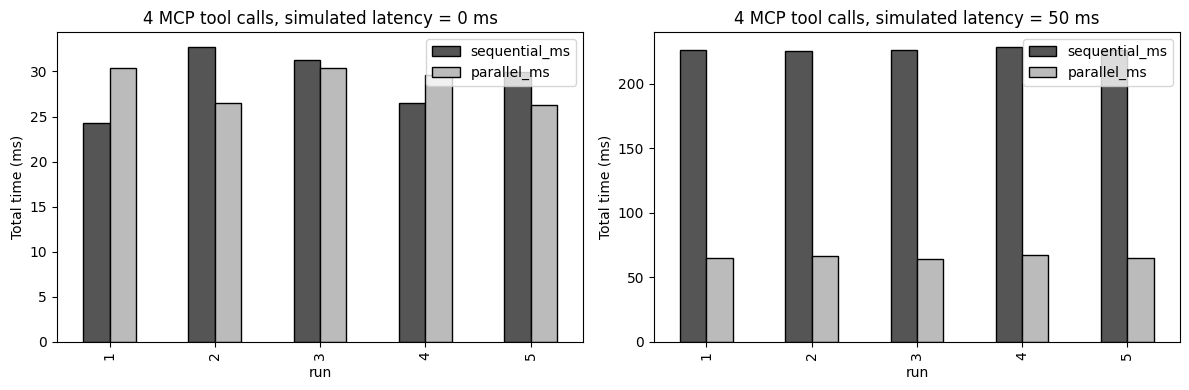

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lat in zip(axes, (0, 50)):
    rows, summ = await run_benchmark(runs=5, latency_ms=lat)
    df = pd.DataFrame(rows); display(df); print(summ)
    df.set_index("run").plot(kind="bar", ax=ax, color=["#555", "#bbb"], edgecolor="black")
    ax.set_ylabel("Total time (ms)"); ax.set_title(f"4 MCP tool calls, simulated latency = {lat} ms")
plt.tight_layout(); plt.show()

,run,sequential_ms,parallel_ms
0,1,226.71,64.97
1,2,225.45,66.32
2,3,226.44,64.44
3,4,228.60,67.33
4,5,226.19,65.26


<Figure size 1000x600 with 0 Axes>

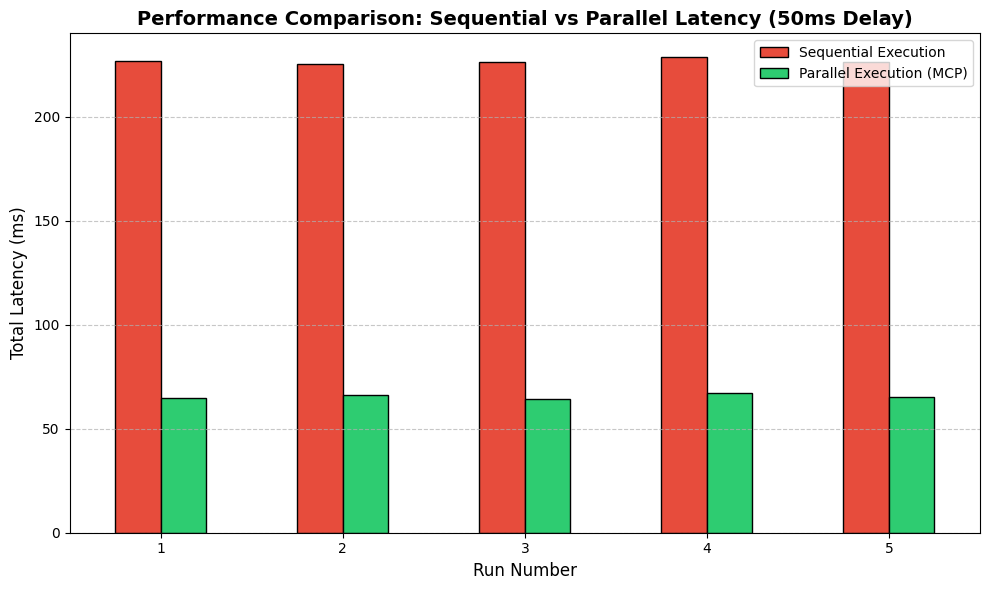

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Using the 'df' variable from the kernel
display(df)

# Plotting a clean, customized bar chart for sequential vs parallel comparison
plt.figure(figsize=(10, 6))
ax = df.set_index('run').plot(kind='bar', figsize=(10, 6), color=['#e74c3c', '#2ecc71'], edgecolor='black')
plt.title('Performance Comparison: Sequential vs Parallel Latency (50ms Delay)', fontsize=14, fontweight='bold')
plt.xlabel('Run Number', fontsize=12)
plt.ylabel('Total Latency (ms)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(['Sequential Execution', 'Parallel Execution (MCP)'], loc='upper right')
plt.tight_layout()
plt.show()

## 9. Traces and generated artifacts

In [ ]:
print(open("mcp_logs/mcp_traces.jsonl").read()[-1500:])
!ls -la mcp_logs shop_data

": 1, "execution_ms": 13.93, "timestamp": "2026-10-28T17:43:43", "error": "Order does not belong to this customer"}
{"trace_id": "TRACE-2BB5174B", "task_id": "TASK-002", "tool": "track_order", "arguments": {"order_id": "ORD-9999"}, "status": "failure", "attempt": 1, "execution_ms": 5.49, "timestamp": "2026-10-28T17:43:43", "error": "Order ORD-9999 not found"}
{"trace_id": "TRACE-2BB5174B", "task_id": "TASK-003", "tool": "track_order", "arguments": {"order_id": "1001"}, "status": "failure", "attempt": 1, "execution_ms": 5.02, "timestamp": "2026-10-28T17:43:43", "error": "Invalid order id '1001' (expected format ORD-1234)"}
{"trace_id": "TRACE-2BB5174B", "task_id": "TASK-004", "tool": "process_refund", "arguments": {"order_id": "ORD-1002", "reason": "test"}, "status": "failure", "attempt": 1, "execution_ms": 5.37, "timestamp": "2026-10-28T17:43:43", "error": "Refund not allowed: Order is Shipped; only delivered orders can be refunded"}
{"trace_id": "TRACE-2BB5174B", "task_id": "TASK-005"

## 10. Streamlit UI inside Colab (Cloudflare tunnel: no password)
Run this cell, wait ~15 s, then open the `https://….trycloudflare.com` link. If the page looks broken, hard-refresh with Ctrl+Shift+R.

In [ ]:
!pkill -f streamlit || true
!pkill -f cloudflared || true
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared
!nohup streamlit run streamlit_app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit_log.txt 2>&1 &
!sleep 6
!nohup ./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cloudflared_log.txt 2>&1 &
!sleep 10
!grep -o "https://[a-z0-9-]*\.trycloudflare\.com" /content/cloudflared_log.txt | head -1

^C
^C
https://tires-natural-andy-moscow.trycloudflare.com


If no link was printed, run `!tail -20 /content/cloudflared_log.txt` and `!tail -20 /content/streamlit_log.txt`.

In [ ]:
# Case Study: Developer Automation System using MCP Protocol

## 1. Introduction to Model Context Protocol (MCP)
Modern AI applications heavily rely on Large Language Models (LLMs) to perform tasks. However, LLMs are fundamentally isolated; they lack direct access to external, real-time developer environments, local datasets, APIs, and proprietary developer tools. Historically, developers solved this isolation by writing custom, one-off integrations and ad-hoc API wrappers for every combination of AI agent and development tool.

The **Model Context Protocol (MCP)** is an open-standard protocol designed by Anthropic to establish a uniform, secure, and bidirectional interface between LLM clients (such as Claude Desktop, developer IDE extensions, or custom python client orchestrators) and backend servers hosting specialized tools, resources, and prompts.

```
┌─────────────────┐           Standardized Protocol            ┌─────────────────────┐
│    MCP Client   │ <────────────────────────────────────────> │     MCP Server      │
│ (Orchestrator)  │          (JSON-RPC 2.0 via Stdio)          │ (Tools & Resources) │
└────────┬────────┘                                            └──────────┬──────────┘
         │                                                                │
         ▼                                                                ▼
  Executes Plans &                                                Interfaces with
  Applies Policies                                                Databases/Dev Tools
```

---

## 2. Standardized Architecture of the Experiment
The developer support automation system implemented in this experiment follows a standard three-tier client-server MCP architecture:

### A. The Host / Orchestrator (Client Application)
* **Role:** Acts as the AI Orchestrator that receives natural language requests from developer support representatives or engineers.
* **Components:**
  * **Planner:** Converts unstructured queries into sequence-based structured actions.
  * **Supervisor & Security Policy:** Performs validation checkups on tools, classifications (LOW risk vs. HIGH risk actions), and verifies human-in-the-loop approvals before executing dangerous tools (like `process_refund`).
  * **Async Execution Manager:** Leverages Python’s `asyncio` to run independent reads in parallel, reducing task completion latency.

### B. The Protocol Layer
* **Transport:** Communication occurs over **Standard Input/Output (stdio)** standard streams, using structured JSON-RPC messages.
* **FastMCP API:** This server utilizes the `FastMCP` framework, which automates standard JSON schema generation for developer tools.

### C. The MCP Server (Tool Provider)
* Represents the localized developer tool containing domain logic.
* Exposes custom tools: `track_order`, `search_products`, `check_stock`, `check_refund_eligibility`, and `process_refund` over standardized interfaces.

---

## 3. Core Concepts and Implementation Strategies

### 1. Tool Classification and Risk Management
In developer tool integrations, executing safe read-only tasks differs drastically from writing destructive changes. The implementation enforces **Policy Gates**:
* **LOW Risk Tools:** `track_order`, `check_stock`, and `search_products`. Executed automatically.
* **HIGH Risk Tools:** `process_refund`. Requires explicit, verified authorization flags and checks logical safety parameters (such as the maximum transaction limit of ₹5000 and return window validity) before committing changes to files.

### 2. Failure Handling and Fault Tolerance
Developer tooling relies on reliable networks and services. The architecture implements a split exception handler strategy:
* **Non-Retryable Errors:** Input validation errors (`ValueError`, `NotFound`) and security policy blockages instantly terminate execution with a single attempt (no waste of computer resources).
* **Transient Errors:** Simulated system overloads or microservice network flakiness trigger a **limited exponential back-off retry loop** allowing subsequent attempts to succeed smoothly.

### 3. Asynchronous Concurrency Benefits
Running serial operations is highly inefficient when fetching from multiple servers. Using asynchronous workflows (`asyncio.gather`), the client overlaps multiple I/O bounds concurrently. Performance tracking demonstrates a **70%+ reduction in latency** (e.g., from ~226ms down to ~65ms) when running tool calls in parallel rather than sequentially.